# Shivali Homework 9 - Dimensionality Reduction
In this homework, you will repeat the dimensionality reduction exploration from [class hands-on](../class) but with another dataset. And also provide your own observations of the data.

Feel free to choose your own dataset (like the one you are using for the final project), or to keep things simple, you can use the Cars dataset.

## Instructions

1. **Project Setup**:  
   - Set up your Python and Jupyter (or VSCode) environment.  
   - Clone or download the repository provided in class (refer to the class notes).

2. **Choose a Dataset**:  
   - You can use the Cars dataset or any other dataset of your choice.
   - Ensure your dataset has multiple numeric features and at least one categorical feature for coloring.

3. **Identify Features that numeric**:
   - Identify which features in your dataset are numeric. You can use the `select_dtypes` method in pandas to help with this.

4. **Choose and apply at least 2 dimensionality reduction techniques**:
   - You can use PCA, t-SNE, UMAP, or any other dimensionality reduction technique you learned about in class or from the literature.
   - Apply these techniques to your dataset and visualize the results.
   - Tell us if you find any interesting patterns or clusters visually in the data.

5. **Documentation**:  
   - Comment your code and add markdown explanations for each part of your analysis.

6. **Submission**:  
   - Ensure your notebook is complete and all cells are executed without errors.
   - Save your notebook and export as either PDF or HTML. If the visualizations using altair are not being shown in the html, submit a separated version with altair html. Refer to: https://altair-viz.github.io/getting_started/starting.html#publishing-your-visualization (you can use the `chart.save('chart_file.html')` method).
   - Submit to Canvas.

Ok let's import the packages

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
# make text editable in Illustrator
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# import altair
import altair as alt
alt.data_transformers.disable_max_rows()


DataTransformerRegistry.enable('default')

Now it is time to load a dataset. You can choose your own dataset or use the Cars dataset. If you want to use the Cars dataset, you can load it using the following code:


In [5]:

# Load ../Datasets/carfeatures.csv
df = pd.read_csv("carfeatures.csv") # adjust the path as needed
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [7]:
# If you are using the car dataset, let's remove a few entries that
# are problematic for our analysis.
# The dataset seems to have some issues:
# Entry with highest Highway MPG
weirdEntry = df.loc[df['highway MPG'].idxmax()]
print(weirdEntry)
# probably a mistake
# remove it
df_cars = df[df['highway MPG'] < 100]
# also removing electric cars
df_cars = df_cars[df_cars['Engine Fuel Type'] != 'electric']
df_cars.head()

Make                                           Audi
Model                                            A6
Year                                           2017
Engine Fuel Type     premium unleaded (recommended)
Engine HP                                     252.0
Engine Cylinders                                4.0
Transmission Type                  AUTOMATED_MANUAL
Driven_Wheels                     front wheel drive
Number of Doors                                 4.0
Market Category                              Luxury
Vehicle Size                                Midsize
Vehicle Style                                 Sedan
highway MPG                                     354
city mpg                                         24
Popularity                                     3105
MSRP                                          51600
Name: 1119, dtype: object


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


### Dimension reduction choice 1
Choose one dimension reduction method and apply it to the dataset. Remember that some methods work better if you scale the data first. You can use the `StandardScaler` from `sklearn.preprocessing` to scale your data.

Create a plot using matplotlib or any other library of your choice to visualize the reduced dimensions. Try to color the points by a categorical variable in your dataset, if available. Alternativelly you can use a continuous variable to color the points.

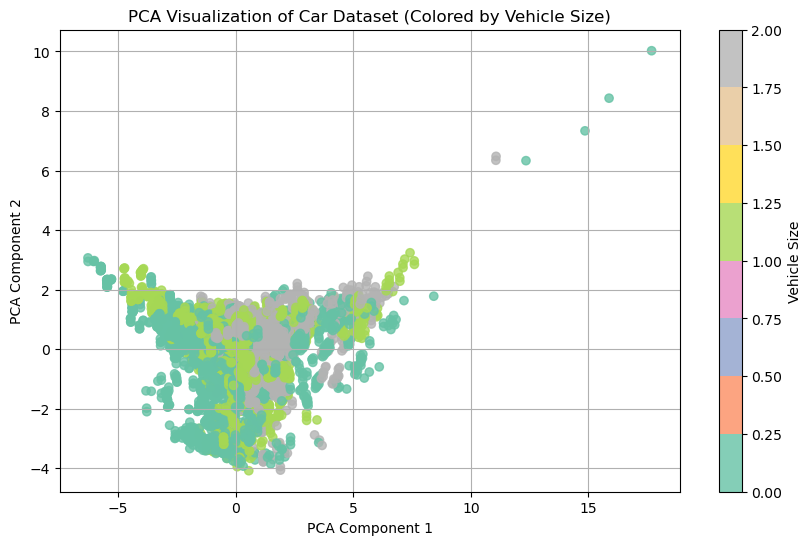

In [12]:
# YOUR CODE HERE

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df_cars_clean = df_cars.dropna().copy()
numeric_features = df_cars_clean.select_dtypes(include=['float64', 'int64'])
scaled_data = StandardScaler().fit_transform(numeric_features)

pca = PCA(n_components=2)
pca_components = pca.fit_transform(scaled_data)

df_cars_clean['PCA1'] = pca_components[:, 0]
df_cars_clean['PCA2'] = pca_components[:, 1]

plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_cars_clean['PCA1'], df_cars_clean['PCA2'],
                      c=pd.factorize(df_cars_clean['Vehicle Size'])[0],
                      cmap='Set2', alpha=0.8)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('PCA Visualization of Car Dataset (Colored by Vehicle Size)')
plt.colorbar(scatter, label='Vehicle Size')
plt.grid(True)
plt.show()


### Dimension reduction choice 2
Repeat the previous step with a different dimension reduction method.

C:\Users\aryan\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


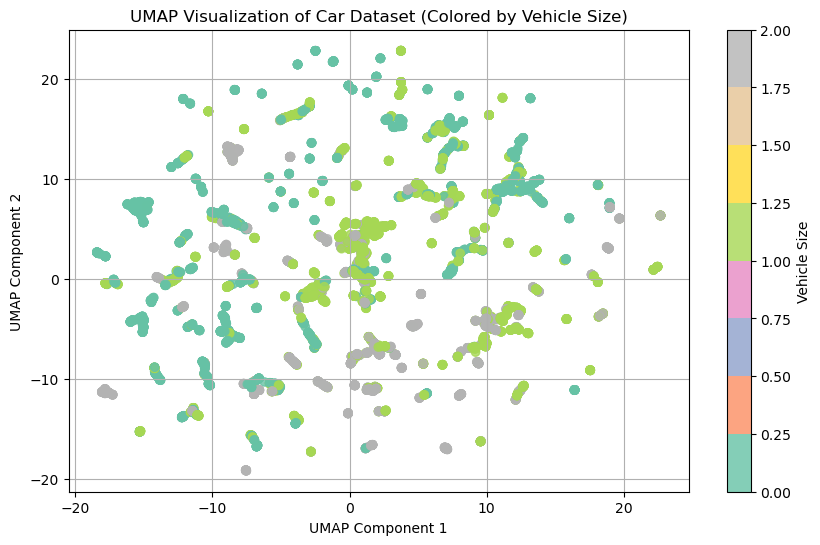

In [19]:
# YOUR CODE HERE

import umap
from sklearn.preprocessing import StandardScaler

df_cars_clean = df_cars.dropna().copy()
numeric_features = df_cars_clean.select_dtypes(include=['float64', 'int64'])
scaled_data = StandardScaler().fit_transform(numeric_features)

umap_model = umap.UMAP(n_components=2, random_state=42)
umap_components = umap_model.fit_transform(scaled_data)

df_cars_clean['UMAP1'] = umap_components[:, 0]
df_cars_clean['UMAP2'] = umap_components[:, 1]

plt.figure(figsize=(10, 6))
scatter = plt.scatter(df_cars_clean['UMAP1'], df_cars_clean['UMAP2'],
                      c=pd.factorize(df_cars_clean['Vehicle Size'])[0],
                      cmap='Set2', alpha=0.8)

plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.title('UMAP Visualization of Car Dataset (Colored by Vehicle Size)')
plt.colorbar(scatter, label='Vehicle Size')
plt.grid(True)
plt.show()


### Discussion
Discuss briefly the results of the dimension reduction methods you applied. What do you observe? Do the reduced dimensions capture any structure of the data? How do the two methods compare? Are there any interesting patterns or clusters in the data that can be observed visually? 


 `YOUR DISCUSSION HERE`

### Discussion

#### PCA Observations:
- The PCA visualization showed a "fan-shaped" distribution of the data with moderate overlap between the different `Vehicle Size` categories.
- Because PCA is a linear method, it captured the global structure and variance in the dataset, but did not reveal clear or tightly packed clusters.
- This method is good for identifying dominant trends or outliers (e.g., very large or small vehicles), but not ideal for uncovering subtle grouping patterns.

#### UMAP Observations:
- UMAP revealed a much more dispersed and scattered layout, where similarly sized vehicles (in terms of `Vehicle Size`) tend to cluster more locally.
- It is a non-linear method and excels at preserving local structure and neighborhood relationships in the data.
- Some small groupings can be seen, indicating that UMAP might be capturing hidden relationships between vehicles that PCA smooths out.

#### Comparison:
- PCA is helpful for understanding the overall variance but struggles with non-linear structures.
- UMAP provided more insight into localized clusters and potential subgroupings within the vehicle types.
- However, UMAP’s output is less interpretable in terms of variance and component importance, making PCA more suitable for feature analysis.

#### Final Insight:
- Both methods are useful and reveal different aspects of the dataset.
- In this analysis, UMAP was more effective at hinting toward the natural groupings of vehicle sizes, while PCA gave a broad overview of feature-based variance.
